<a href="https://colab.research.google.com/github/juchi6/data-science-lab/blob/main/logistics_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multiple Linear Regression: Logistics Delivery Delay

**Model:** $\hat{y} = \hat{\beta}_0 + \hat{\beta}_1 x_1 + \hat{\beta}_2 x_2 + \hat{\beta}_3 x_3$

| Variable | Description |
|---|---|
| $y$ | Delay Time (minutes) |
| $x_1$ | Route Distance (tens of km) |
| $x_2$ | Traffic Congestion Index (1–10) |
| $x_3$ | Peak-Hour Indicator (0 or 1) |

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from fractions import Fraction

# Display settings
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.float_format', '{:.4f}'.format)

## 1 · Data & Design Matrix

In [ ]:
# --- Raw data ---
data = pd.DataFrame({
    'Route': range(1, 9),
    'x1_distance':  [10, 14, 19, 24, 28, 33, 38, 42],
    'x2_traffic':   [ 2,  3,  2,  5,  4,  6,  5,  7],
    'x3_peak':      [ 0,  1,  0,  1,  0,  1,  0,  1],
    'y_delay':      [44, 58, 61, 79, 82, 99,101,118]
})

print("=== Route Observation Dataset ===")
print(data.to_string(index=False))

=== Route Observation Dataset ===
 Route  x1_distance  x2_traffic  x3_peak  y_delay
     1           10           2        0       44
     2           14           3        1       58
     3           19           2        0       61
     4           24           5        1       79
     5           28           4        0       82
     6           33           6        1       99
     7           38           5        0      101
     8           42           7        1      118


In [ ]:
# --- Build design matrix X and response vector y ---
y  = data['y_delay'].values.astype(float)
x1 = data['x1_distance'].values.astype(float)
x2 = data['x2_traffic'].values.astype(float)
x3 = data['x3_peak'].values.astype(float)

n = len(y)         # 8 observations
p = 4              # intercept + 3 predictors
df = n - p         # residual degrees of freedom = 4

X = np.column_stack([np.ones(n), x1, x2, x3])

print("Design Matrix X  (ones | x1 | x2 | x3):")
print(pd.DataFrame(X, columns=['1', 'x1','x2','x3']).to_string(index=False))

Design Matrix X  (ones | x1 | x2 | x3):
     1      x1     x2     x3
1.0000 10.0000 2.0000 0.0000
1.0000 14.0000 3.0000 1.0000
1.0000 19.0000 2.0000 0.0000
1.0000 24.0000 5.0000 1.0000
1.0000 28.0000 4.0000 0.0000
1.0000 33.0000 6.0000 1.0000
1.0000 38.0000 5.0000 0.0000
1.0000 42.0000 7.0000 1.0000


## 2 · Normal Equations & OLS Solution

$$\mathbf{X'X}\,\hat{\boldsymbol{\beta}} = \mathbf{X'y} \quad\Longrightarrow\quad \hat{\boldsymbol{\beta}} = (\mathbf{X'X})^{-1}\mathbf{X'y}$$

In [ ]:
XtX     = X.T @ X
Xty     = X.T @ y
XtX_inv = np.linalg.inv(XtX)
beta    = XtX_inv @ Xty

print("X'X =")
print(pd.DataFrame(XtX, columns=['1','x1','x2','x3'], index=['1','x1','x2','x3']))
print()
print("X'y =", Xty)
print()
print("(X'X)⁻¹ =")
print(np.round(XtX_inv, 6))
print()

labels = ['β₀ (intercept)', 'β₁ (distance)', 'β₂ (traffic)', 'β₃ (peak)']
print("=== OLS Coefficient Estimates ===")
for lbl, b in zip(labels, beta):
    print(f"  {lbl:20s} = {b:+.6f}")

print(f"\nFitted model:")
print(f"  ŷ = {beta[0]:.4f} + {beta[1]:.4f}·x₁ + {beta[2]:.4f}·x₂ + {beta[3]:.4f}·x₃")

X'X =
          1        x1        x2       x3
1    8.0000  208.0000   34.0000   4.0000
x1 208.0000 6314.0000 1014.0000 113.0000
x2  34.0000 1014.0000  168.0000  21.0000
x3   4.0000  113.0000   21.0000   4.0000

X'y = [  642. 18664.  3032.   354.]

(X'X)⁻¹ =
[[ 0.9327 -0.0047 -0.1755  0.1222]
 [-0.0047  0.0178 -0.1286  0.177 ]
 [-0.1755 -0.1286  0.9934 -1.4083]
 [ 0.1222  0.177  -1.4083  2.5199]]

=== OLS Coefficient Estimates ===
  β₀ (intercept)       = +21.693257
  β₁ (distance)        = +1.910187
  β₂ (traffic)         = +1.519943
  β₃ (peak)            = +4.864275

Fitted model:
  ŷ = 21.6933 + 1.9102·x₁ + 1.5199·x₂ + 4.8643·x₃


## 3 · Residuals, SSE, and Error Variance

In [ ]:
y_hat     = X @ beta
residuals = y - y_hat

resid_df = pd.DataFrame({
    'Route':    data['Route'],
    'y':        y,
    'ŷ':        np.round(y_hat, 4),
    'e = y−ŷ':  np.round(residuals, 4),
    'e²':       np.round(residuals**2, 6)
})
print(resid_df.to_string(index=False))

SSE = np.sum(residuals**2)
s2  = SSE / df
s   = np.sqrt(s2)

y_bar = np.mean(y)
SST   = np.sum((y - y_bar)**2)
SSR   = SST - SSE
R2    = SSR / SST

print(f"\nSSE = {SSE:.6f}")
print(f"df  = n − p = {n} − {p} = {df}")
print(f"s²  = SSE/df = {s2:.6f}")
print(f"s   = {s:.6f} min")
print(f"R²  = {R2:.6f}  ({100*R2:.2f}%)")

 Route        y        ŷ  e = y−ŷ     e²
     1  44.0000  43.8350   0.1650 0.0272
     2  58.0000  57.8600   0.1400 0.0196
     3  61.0000  61.0267  -0.0267 0.0007
     4  79.0000  80.0017  -1.0017 1.0034
     5  82.0000  81.2582   0.7418 0.5502
     6  99.0000  98.7133   0.2867 0.0822
     7 101.0000 101.8801  -0.8801 0.7745
     8 118.0000 117.4250   0.5750 0.3307

SSE = 2.788522
df  = n − p = 8 − 4 = 4
s²  = SSE/df = 0.697131
s   = 0.834943 min
R²  = 0.999365  (99.94%)


## 4 · Standard Errors & t-Tests

$$\text{Var}(\hat{\boldsymbol{\beta}}) = s^2(\mathbf{X'X})^{-1} \qquad SE(\hat{\beta}_j) = s\sqrt{[(\mathbf{X'X})^{-1}]_{jj}}$$

$$t_j = \frac{\hat{\beta}_j}{SE(\hat{\beta}_j)}, \quad df = 4, \quad t_{0.025,4} = 2.7764$$

In [ ]:
var_beta = s2 * XtX_inv
SE_beta  = np.sqrt(np.diag(var_beta))
t_stats  = beta / SE_beta
p_values = [2 * (1 - stats.t.cdf(abs(t), df)) for t in t_stats]
t_crit   = stats.t.ppf(0.975, df)

print(f"Critical value: t_{{0.025, {df}}} = {t_crit:.4f}")
print()

summary = pd.DataFrame({
    'Coefficient': ['β₀','β₁','β₂','β₃'],
    'Estimate':    np.round(beta, 6),
    'SE':          np.round(SE_beta, 6),
    't-stat':      np.round(t_stats, 4),
    'p-value':     [f"{p:.4f}" for p in p_values],
    'Significant?': ['✓' if abs(t) > t_crit else '✗' for t in t_stats]
})
print(summary.to_string(index=False))

Critical value: t_{0.025, 4} = 2.7764

Coefficient  Estimate     SE  t-stat p-value Significant?
         β₀   21.6933 0.8064 26.9026  0.0000            ✓
         β₁    1.9102 0.1114 17.1524  0.0001            ✓
         β₂    1.5199 0.8322  1.8265  0.1418            ✗
         β₃    4.8643 1.3254  3.6700  0.0214            ✓


## 5 · Collinearity Diagnostic

In [ ]:
r_x1x2 = np.corrcoef(x1, x2)[0, 1]
VIF_x2  = 1 / (1 - r_x1x2**2)

print(f"Pearson r(x1, x2)         = {r_x1x2:.4f}")
print(f"r²                        = {r_x1x2**2:.4f}")
print(f"VIF(x2) ≈ 1/(1−r²)       = {VIF_x2:.4f}")
print(f"SE inflation factor √VIF  = {np.sqrt(VIF_x2):.4f}")
print()
print("Interpretation:")
print(f"  SE(β₂) = {SE_beta[2]:.4f} is inflated ~{np.sqrt(VIF_x2):.1f}× due to collinearity.")
print(f"  t(β₂) = {t_stats[2]:.4f} < {t_crit:.4f} → β₂ NOT significant at α=0.05")
print("  Despite x2 being physically meaningful, collinearity prevents")
print("  reliable separation of its effect from x1 with only 8 observations.")

Pearson r(x1, x2)         = 0.8909
r²                        = 0.7938
VIF(x2) ≈ 1/(1−r²)       = 4.8488
SE inflation factor √VIF  = 2.2020

Interpretation:
  SE(β₂) = 0.8322 is inflated ~2.2× due to collinearity.
  t(β₂) = 1.8265 < 2.7764 → β₂ NOT significant at α=0.05
  Despite x2 being physically meaningful, collinearity prevents
  reliable separation of its effect from x1 with only 8 observations.


## 6 · Point Prediction & Intervals

**New route:** $x_1 = 26,\; x_2 = 4,\; x_3 = 1$

$$\hat{y}_0 = \mathbf{x}_0^T\hat{\boldsymbol{\beta}}, \qquad h_{00} = \mathbf{x}_0^T(\mathbf{X'X})^{-1}\mathbf{x}_0$$

**95% CI (mean response):** $\hat{y}_0 \pm t_{0.025,4}\cdot s\sqrt{h_{00}}$

**95% PI (individual):**   $\hat{y}_0 \pm t_{0.025,4}\cdot s\sqrt{1 + h_{00}}$

In [ ]:
x0     = np.array([1, 26, 4, 1], dtype=float)
y0_hat = x0 @ beta

h00     = x0 @ XtX_inv @ x0
SE_mean = s * np.sqrt(h00)
SE_pred = s * np.sqrt(1 + h00)

CI = (y0_hat - t_crit * SE_mean,  y0_hat + t_crit * SE_mean)
PI = (y0_hat - t_crit * SE_pred,  y0_hat + t_crit * SE_pred)

print(f"New route profile:  x₁={x0[1]}, x₂={x0[2]}, x₃={int(x0[3])}")
print()
print(f"Point prediction    ŷ₀         = {y0_hat:.4f} min")
print(f"Leverage            h₀₀        = {h00:.6f}")
print()
print(f"SE (mean response)             = {SE_mean:.6f} min")
print(f"95% CI for E(Y|x₀)            = ({CI[0]:.4f}, {CI[1]:.4f}) min")
print()
print(f"SE (individual prediction)     = {SE_pred:.6f} min")
print(f"95% PI for Y_new               = ({PI[0]:.4f}, {PI[1]:.4f}) min")

New route profile:  x₁=26.0, x₂=4.0, x₃=1

Point prediction    ŷ₀         = 82.3022 min
Leverage            h₀₀        = 1.169154

SE (mean response)             = 0.902803 min
95% CI for E(Y|x₀)            = (79.7956, 84.8087) min

SE (individual prediction)     = 1.229709 min
95% PI for Y_new               = (78.8879, 85.7164) min


## 7 · Diagnostic Plots

FileNotFoundError: [Errno 2] No such file or directory: '/home/claude/regression_diagnostics.png'

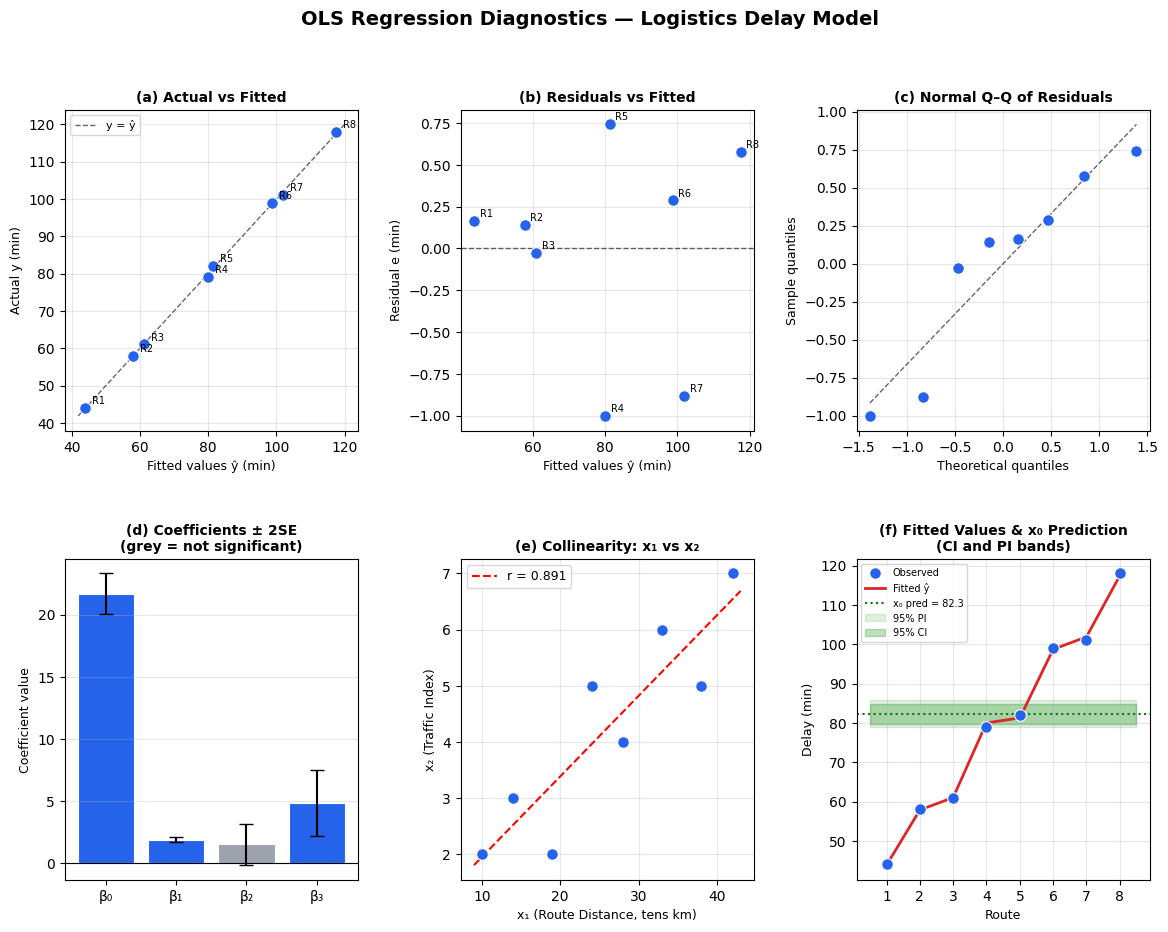

In [ ]:
fig = plt.figure(figsize=(14, 10))
fig.suptitle('OLS Regression Diagnostics — Logistics Delay Model',
             fontsize=14, fontweight='bold', y=0.98)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

colors = ['#2563EB', '#DC2626']

# --- (a) Actual vs Fitted ---
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(y_hat, y, color=colors[0], zorder=3, s=70, edgecolors='white', linewidth=0.8)
lims = [min(y_hat.min(), y.min()) - 2, max(y_hat.max(), y.max()) + 2]
ax1.plot(lims, lims, 'k--', lw=1, alpha=0.6, label='y = ŷ')
for i, (xi, yi) in enumerate(zip(y_hat, y)):
    ax1.annotate(f'R{i+1}', (xi, yi), textcoords='offset points', xytext=(5,3), fontsize=7)
ax1.set_xlabel('Fitted values ŷ (min)', fontsize=9)
ax1.set_ylabel('Actual y (min)', fontsize=9)
ax1.set_title('(a) Actual vs Fitted', fontsize=10, fontweight='bold')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# --- (b) Residuals vs Fitted ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.scatter(y_hat, residuals, color=colors[0], zorder=3, s=70, edgecolors='white', linewidth=0.8)
ax2.axhline(0, color='k', lw=1, ls='--', alpha=0.6)
for i, (xi, ri) in enumerate(zip(y_hat, residuals)):
    ax2.annotate(f'R{i+1}', (xi, ri), textcoords='offset points', xytext=(4,3), fontsize=7)
ax2.set_xlabel('Fitted values ŷ (min)', fontsize=9)
ax2.set_ylabel('Residual e (min)', fontsize=9)
ax2.set_title('(b) Residuals vs Fitted', fontsize=10, fontweight='bold')
ax2.grid(True, alpha=0.3)

# --- (c) Q-Q Plot ---
ax3 = fig.add_subplot(gs[0, 2])
std_res = residuals / s
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist='norm')
ax3.scatter(osm, osr, color=colors[0], zorder=3, s=70, edgecolors='white', linewidth=0.8)
qq_line_x = np.array([min(osm), max(osm)])
ax3.plot(qq_line_x, slope*qq_line_x + intercept, 'k--', lw=1, alpha=0.6)
ax3.set_xlabel('Theoretical quantiles', fontsize=9)
ax3.set_ylabel('Sample quantiles', fontsize=9)
ax3.set_title('(c) Normal Q–Q of Residuals', fontsize=10, fontweight='bold')
ax3.grid(True, alpha=0.3)

# --- (d) Coefficient bar chart with ±2 SE bands ---
ax4 = fig.add_subplot(gs[1, 0])
bar_colors = [colors[0] if abs(t) > t_crit else '#9CA3AF' for t in t_stats]
bars = ax4.bar(['β₀','β₁','β₂','β₃'], beta, color=bar_colors,
               yerr=2*SE_beta, capsize=5, edgecolor='white', linewidth=0.8)
ax4.axhline(0, color='k', lw=0.8)
ax4.set_ylabel('Coefficient value', fontsize=9)
ax4.set_title('(d) Coefficients ± 2SE\n(grey = not significant)', fontsize=10, fontweight='bold')
ax4.grid(True, alpha=0.3, axis='y')

# --- (e) Collinearity: x1 vs x2 ---
ax5 = fig.add_subplot(gs[1, 1])
ax5.scatter(x1, x2, color=colors[0], zorder=3, s=70, edgecolors='white', linewidth=0.8)
m, b_lin, r_val, *_ = stats.linregress(x1, x2)
xl = np.linspace(x1.min()-1, x1.max()+1, 100)
ax5.plot(xl, m*xl + b_lin, 'r--', lw=1.5, label=f'r = {r_val:.3f}')
ax5.set_xlabel('x₁ (Route Distance, tens km)', fontsize=9)
ax5.set_ylabel('x₂ (Traffic Index)', fontsize=9)
ax5.set_title('(e) Collinearity: x₁ vs x₂', fontsize=10, fontweight='bold')
ax5.legend(fontsize=9)
ax5.grid(True, alpha=0.3)

# --- (f) Prediction interval visualisation ---
ax6 = fig.add_subplot(gs[1, 2])
routes = np.arange(1, n+1)
ax6.scatter(routes, y, color=colors[0], zorder=5, s=70, label='Observed', edgecolors='white', linewidth=0.8)
ax6.plot(routes, y_hat, color=colors[1], lw=2, label='Fitted ŷ', zorder=4)
# Add prediction for x0
ax6.axhline(y0_hat, color='green', lw=1.5, ls=':', label=f'x₀ pred = {y0_hat:.1f}')
ax6.fill_between([0.5, 8.5], [PI[0]]*2, [PI[1]]*2, alpha=0.12, color='green', label='95% PI')
ax6.fill_between([0.5, 8.5], [CI[0]]*2, [CI[1]]*2, alpha=0.25, color='green', label='95% CI')
ax6.set_xticks(routes)
ax6.set_xlabel('Route', fontsize=9)
ax6.set_ylabel('Delay (min)', fontsize=9)
ax6.set_title('(f) Fitted Values & x₀ Prediction\n(CI and PI bands)', fontsize=10, fontweight='bold')
ax6.legend(fontsize=7, loc='upper left')
ax6.grid(True, alpha=0.3)

plt.savefig('/home/claude/regression_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plots saved to regression_diagnostics.png")

## 8 · Full Results Summary

In [ ]:
print("="*60)
print(" FULL REGRESSION SUMMARY")
print("="*60)
print(f"  n = {n}, p = {p}, df = {df}")
print()
print("  Fitted model:")
print(f"  ŷ = {beta[0]:.4f} + {beta[1]:.4f}·x₁ + {beta[2]:.4f}·x₂ + {beta[3]:.4f}·x₃")
print()
print(f"  SSE  = {SSE:.4f}")
print(f"  s²   = {s2:.4f}")
print(f"  s    = {s:.4f} min")
print(f"  R²   = {R2:.6f}  ({100*R2:.2f}%)")
print()
print("  Coefficient Table:")
print(f"  {'':4s} {'Estimate':>12s} {'SE':>12s} {'t-stat':>10s} {'p-value':>10s} {'Sig':>5s}")
sig_syms = ['***','***','   ','*  ']
for j, (lbl, b, se, t, pv, sig) in enumerate(
        zip(['β₀','β₁','β₂','β₃'], beta, SE_beta, t_stats, p_values, sig_syms)):
    print(f"  {lbl:4s} {b:12.4f} {se:12.4f} {t:10.4f} {pv:10.4f} {sig:>5s}")
print("  Signif. codes: *** p<0.001  * p<0.05")
print()
print("  Collinearity (x₁ vs x₂):")
print(f"  r = {r_x1x2:.4f},  VIF(x₂) ≈ {VIF_x2:.2f}")
print()
print("  Prediction for x₀ = [26, 4, 1]:")
print(f"  ŷ₀                = {y0_hat:.4f} min")
print(f"  95% CI (mean)     = ({CI[0]:.4f}, {CI[1]:.4f}) min")
print(f"  95% PI (individ.) = ({PI[0]:.4f}, {PI[1]:.4f}) min")
print("="*60)

 FULL REGRESSION SUMMARY
  n = 8, p = 4, df = 4

  Fitted model:
  ŷ = 21.6933 + 1.9102·x₁ + 1.5199·x₂ + 4.8643·x₃

  SSE  = 2.7885
  s²   = 0.6971
  s    = 0.8349 min
  R²   = 0.999365  (99.94%)

  Coefficient Table:
           Estimate           SE     t-stat    p-value   Sig
  β₀        21.6933       0.8064    26.9026     0.0000   ***
  β₁         1.9102       0.1114    17.1524     0.0001   ***
  β₂         1.5199       0.8322     1.8265     0.1418      
  β₃         4.8643       1.3254     3.6700     0.0214   *  
  Signif. codes: *** p<0.001  * p<0.05

  Collinearity (x₁ vs x₂):
  r = 0.8909,  VIF(x₂) ≈ 4.85

  Prediction for x₀ = [26, 4, 1]:
  ŷ₀                = 82.3022 min
  95% CI (mean)     = (79.7956, 84.8087) min
  95% PI (individ.) = (78.8879, 85.7164) min
